# Customer Behaviour Analysis: Predicting High-Spending and Low-Spending Customers Using Logistic Regression

**Subject:** Statistics for Artificial Intelligence & Data Science  
**Level:** Third-Year Engineering Academic Project  
**Dataset:** Mall Customer Segmentation Dataset (`data/Mall_Customers.csv`)  
**Currency Benchmark:** 1 USD = 83.0 INR (Fixed conversion rate)

---

## 1. Project Objectives
1. Perform in-depth **Exploratory Data Analysis (EDA)** and data validation.
2. Formulate and test statistical hypotheses (**Two-Sample t-Test**, **One-Way ANOVA**).
3. Evaluate linear associations using **Correlation Analysis** and **OLS Linear Regression**.
4. Assess feature scaling impact (**StandardScaler** vs **MinMaxScaler**).
5. Build and interpret **Binary Logistic Regression** ($P(Y=1 \mid X)$) for customer spending classification.
6. Quantify uncertainty via **Non-parametric Bootstrap Resampling** (1000 iterations).
7. Apply **Principal Component Analysis (PCA)** for dimensionality reduction and orthogonal feature projection.
8. Validate model generalizability using **5-Fold Stratified Cross-Validation**.


### 2. Library Imports & Environment Configuration

In [1]:
import sys
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.multicomp import pairwise_tukeyhsd

# Add src module to python path
sys.path.append(os.path.abspath('..'))
from src.data_preprocessing import (
    USD_TO_INR, format_indian_currency, load_raw_data, inspect_data_integrity,
    preprocess_data, get_feature_target_split, prepare_train_test_datasets, apply_scaling
)
from src.descriptive_statistics import (
    calculate_descriptive_stats, get_formatted_descriptive_table, get_statistical_interpretations
)
from src.hypothesis_testing import (
    test_gender_vs_spending_score, get_hypothesis_summary_table
)
from src.anova_analysis import (
    perform_income_spending_anova
)
from src.correlation_regression import (
    compute_correlation_analysis, fit_linear_regression
)
from src.logistic_regression import (
    compare_feature_scaling, train_logistic_regression_pipeline, predict_customer_category
)
from src.bootstrap_analysis import (
    bootstrap_statistic_ci, bootstrap_model_accuracy, run_full_bootstrap_suite
)
from src.pca_analysis import (
    perform_pca_analysis
)
from src.model_evaluation import (
    evaluate_classifier, perform_kfold_cv, compare_generalization
)

# Plot styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['font.size'] = 11
print(f"Environment initialized. Fixed USD to INR conversion rate: ₹{USD_TO_INR:.1f} / $1 USD")


Environment initialized. Fixed USD to INR conversion rate: ₹83.0 / $1 USD


## 3. Data Ingestion, Integrity Validation & Currency Conversion

We convert `Annual Income (k$)` to `Annual_Income_INR` using `Annual_Income_INR = Annual_Income_USD_K * 1000 * 83.0`.
We also engineer the binary target variable `Spending_Category`:
- **High Spender ($1$):** `Spending Score >= 50`
- **Low Spender ($0$):** `Spending Score < 50`


In [2]:
# Load data
raw_df = load_raw_data('../data/Mall_Customers.csv' if os.path.exists('../data/Mall_Customers.csv') else 'data/Mall_Customers.csv')
integrity = inspect_data_integrity(raw_df)
print("Data Integrity Report:")
for k, v in integrity.items():
    print(f" - {k}: {v}")

# Preprocess data
df_clean = preprocess_data(raw_df)
df_clean[['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Annual_Income_INR_Formatted', 'Spending Score (1-100)', 'Spending_Category_Label']].head(10)


Data Integrity Report:
 - shape: (200, 5)
 - columns: ['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']
 - dtypes: {'CustomerID': 'int64', 'Gender': 'str', 'Age': 'int64', 'Annual Income (k$)': 'int64', 'Spending Score (1-100)': 'int64'}
 - missing_values: {'CustomerID': 0, 'Gender': 0, 'Age': 0, 'Annual Income (k$)': 0, 'Spending Score (1-100)': 0}
 - total_missing: 0
 - duplicate_rows: 0
 - age_range: (18, 70)
 - income_k_range: (15.0, 137.0)
 - spending_score_range: (1, 99)


,CustomerID,Gender,Age,Annual Income (k$),Annual_Income_INR_Formatted,Spending Score (1-100),Spending_Category_Label
0,1,Male,19,15,"₹12,45,000",39,Low Spender
1,2,Male,21,15,"₹12,45,000",81,High Spender
2,3,Female,20,16,"₹13,28,000",6,Low Spender
3,4,Female,23,16,"₹13,28,000",77,High Spender
4,5,Female,31,17,"₹14,11,000",40,Low Spender
5,6,Female,22,17,"₹14,11,000",76,High Spender
6,7,Female,35,18,"₹14,94,000",6,Low Spender
7,8,Female,23,18,"₹14,94,000",94,High Spender
8,9,Male,64,19,"₹15,77,000",3,Low Spender
9,10,Female,30,19,"₹15,77,000",72,High Spender


## 4. Exploratory Data Analysis (EDA)

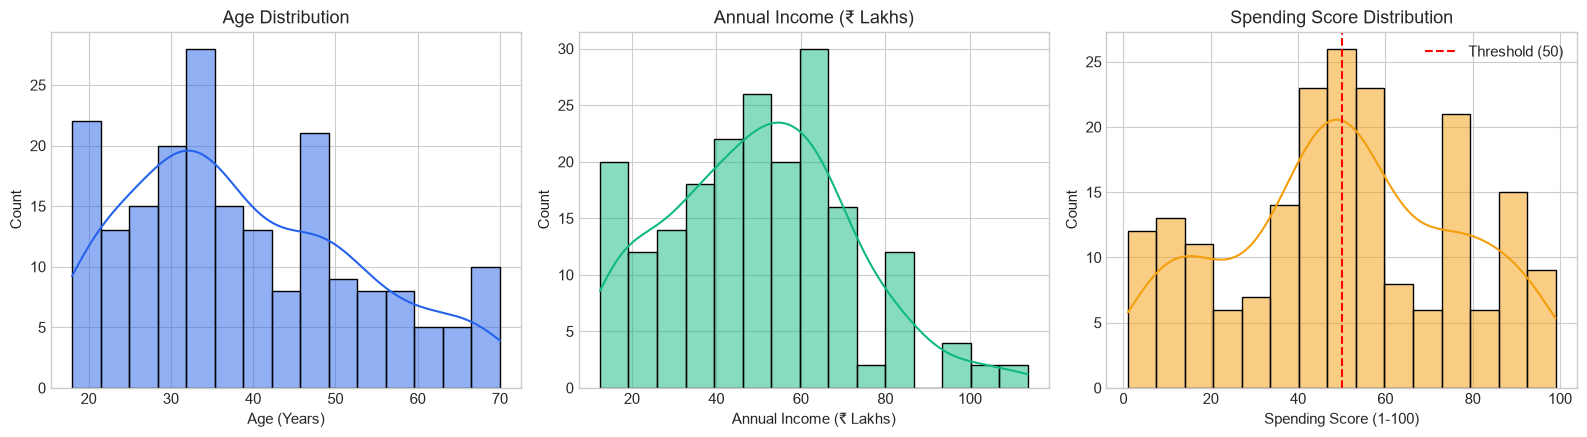

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Age Distribution
sns.histplot(df_clean['Age'], kde=True, color='#2563EB', ax=axes[0], bins=15)
axes[0].set_title('Age Distribution')
axes[0].set_xlabel('Age (Years)')

# Income in INR Distribution
sns.histplot(df_clean['Annual_Income_INR'] / 100000, kde=True, color='#10B981', ax=axes[1], bins=15)
axes[1].set_title('Annual Income (₹ Lakhs)')
axes[1].set_xlabel('Annual Income (₹ Lakhs)')

# Spending Score Distribution
sns.histplot(df_clean['Spending Score (1-100)'], kde=True, color='#F59E0B', ax=axes[2], bins=15)
axes[2].axvline(50, color='red', linestyle='--', label='Threshold (50)')
axes[2].set_title('Spending Score Distribution')
axes[2].set_xlabel('Spending Score (1-100)')
axes[2].legend()

plt.tight_layout()
plt.show()


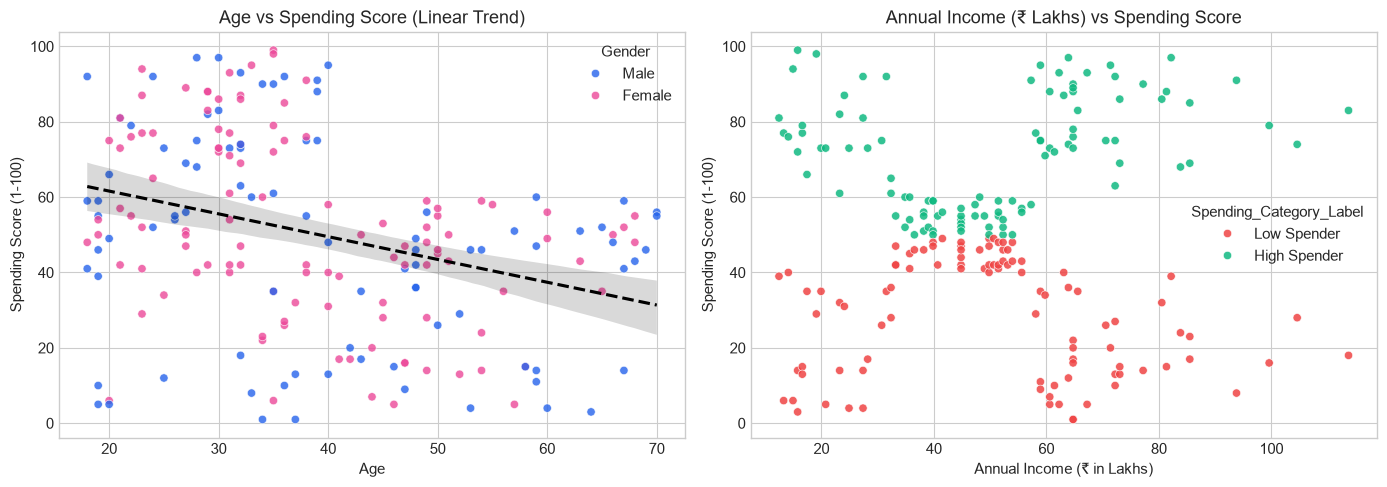

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Age vs Spending Score
sns.scatterplot(data=df_clean, x='Age', y='Spending Score (1-100)', hue='Gender', palette=['#2563EB', '#EC4899'], alpha=0.8, ax=axes[0])
sns.regplot(data=df_clean, x='Age', y='Spending Score (1-100)', scatter=False, ax=axes[0], color='black', line_kws={'linestyle': '--'})
axes[0].set_title('Age vs Spending Score (Linear Trend)')

# Income in Lakhs vs Spending Score
sns.scatterplot(data=df_clean, x=df_clean['Annual_Income_INR']/100000, y=df_clean['Spending Score (1-100)'], 
                hue=df_clean['Spending_Category_Label'], palette=['#EF4444', '#10B981'], alpha=0.85, ax=axes[1])
axes[1].set_title('Annual Income (₹ Lakhs) vs Spending Score')
axes[1].set_xlabel('Annual Income (₹ in Lakhs)')

plt.tight_layout()
plt.show()


## 5. Descriptive Statistics & Probability Distribution Analysis

In [5]:
stats_df = calculate_descriptive_stats(df_clean)
formatted_stats = get_formatted_descriptive_table(stats_df)
print("Comprehensive Descriptive Statistics:")
formatted_stats


Comprehensive Descriptive Statistics:


,Variable,Mean,Median,Mode,Min,Max,Range,Std Dev (s),IQR,Skewness,Excess Kurtosis,Shapiro p-value,Shape Assessment
0,Age,38.85,36.00,32.00,18.00,70.00,52.00,13.97,20.25,0.486,-0.672,2.7109e-06,Approximately Symmetric; Non-Normal (p < 0.05)
1,Annual Income (k$),60.56,61.50,54.00,15.00,137.00,122.00,26.26,36.50,0.322,-0.098,3.5365e-03,Approximately Symmetric; Non-Normal (p < 0.05)
2,Annual_Income_INR,"₹50,26,480","₹51,04,500","₹44,82,000","₹12,45,000","₹1,13,71,000","₹1,01,26,000","₹21,79,972","₹30,29,500",0.322,-0.098,3.5365e-03,Approximately Symmetric; Non-Normal (p < 0.05)
3,Spending Score (1-100),50.20,50.00,42.00,1.00,99.00,98.00,25.82,38.25,-0.047,-0.827,2.4230e-04,Approximately Symmetric; Non-Normal (p < 0.05)


In [6]:
interpretations = get_statistical_interpretations(stats_df)
for var, text in interpretations.items():
    print(f"\n[{var}]:\n{text}")



[Age]:
The mean customer age is 38.9 years with a standard deviation of 14.0 years. The median age (36.0 years) is close to the mean, reflecting a mild positive skew (0.486). Customers span from 18 to 70 years, with the middle 50% (IQR) located between 28.8 and 49.0 years.

[Annual Income (k$)]:
Average annual income is $60.56k with a standard deviation of $26.26k. The income spans from $15.0k to $137.0k with an IQR of $36.5k.

[Annual_Income_INR]:
The average annual income in Indian Rupees is ₹50,26,480 (Std Dev: ₹21,79,972). The median income is ₹51,04,500. The positive skew (0.322) indicates a modest right tail with high-earning individuals reaching up to ₹1,13,71,000.

[Spending Score (1-100)]:
The mean spending score is 50.20/100 and median is 50.0/100. The dispersion is substantial (Std Dev = 25.82, Range = 98), showing high heterogeneity in consumer spending behavior across mall visitors.


## 6. Hypothesis Testing: Gender vs Spending Score

- **Null Hypothesis ($H_0$):** $\mu_{\text{Male}} = \mu_{\text{Female}}$ (No difference in mean spending score between genders).
- **Alternative Hypothesis ($H_1$):** $\mu_{\text{Male}} 
eq \mu_{\text{Female}}$ (Statistically significant difference).
- **Significance Level:** $\alpha = 0.05$.


In [7]:
hyp_res = test_gender_vs_spending_score(df_clean, alpha=0.05)
summary_table = get_hypothesis_summary_table(hyp_res)
print("Hypothesis Test Results Summary:")
summary_table


Hypothesis Test Results Summary:


,Parameter / Metric,Value
0,Null Hypothesis (H0),H0: mu_Male = mu_Female (No difference in mean...
1,Alternative Hypothesis (H1),H1: mu_Male != mu_Female (Significant differen...
2,Significance Level (α),0.05
3,Male Sample Size (n1),88
4,Female Sample Size (n2),112
5,Male Mean Spending Score,48.51
6,Female Mean Spending Score,51.53
7,Levene's Test p-value (Equal Variance),0.1275
8,Parametric Test Applied,Student's Two-Sample Independent t-Test (Equal...
9,t-statistic,-0.8190


## 7. Analysis of Variance (One-Way ANOVA): Income Groups vs Spending Score

- **Null Hypothesis ($H_0$):** $\mu_{\text{Low}} = \mu_{\text{Medium}} = \mu_{\text{High}}$ (Mean spending score is equal across income tiers).
- **Alternative Hypothesis ($H_1$):** At least one income group has a different mean spending score.


In [8]:
anova_res = perform_income_spending_anova(df_clean, alpha=0.05)
print("Income Groups Summary:")
print(anova_res['group_stats_df'])
print("\nOne-Way ANOVA Table:")
print(anova_res['anova_table'])
print(f"\nDecision: {anova_res['decision']}")
print(f"Conclusion: {anova_res['conclusion']}")


Income Groups Summary:
                      Income Group  Sample Size (n)  Mean Spending Score  \
0            Low Income (< ₹33.2L)               46            49.739130   
1  Medium Income (₹33.2L - ₹66.4L)              116            50.267241   
2           High Income (> ₹66.4L)               38            50.552632   

     Std Dev  Median  Min   Max  
0  31.478695    50.5  3.0  99.0  
1  20.273932    50.0  1.0  97.0  
2  33.218928    51.0  5.0  97.0  

One-Way ANOVA Table:
              Source of Variation  Sum of Squares (SS)  \
0      Between Groups (Treatment)            15.020181   
1  Within Groups (Error/Residual)        132688.979819   
2                           Total        132704.000000   

   Degrees of Freedom (df)  Mean Square (MS)  F-Statistic   p-value  
0                        2          7.510090      0.01115  0.988913  
1                      197        673.548121          NaN       NaN  
2                      199               NaN          NaN       NaN  



## 8. Correlation Analysis & Multiple Linear Regression (OLS)

*Note: Correlation indicates linear association and does not imply causation.*


In [9]:
corr_res = compute_correlation_analysis(df_clean)
print("Pearson Correlation Matrix:")
print(corr_res['pearson_corr'])

lin_res = fit_linear_regression(df_clean)
print("\nMultiple Linear Regression Parameter Summary:")
print(lin_res['summary_table'])
print(f"\nModel Fit Metrics:")
for k, v in lin_res['metrics'].items():
    print(f" - {k}: {v:.4f}")


Pearson Correlation Matrix:
                             Age  Annual Income (k$)  Spending Score (1-100)
Age                     1.000000           -0.012398               -0.327227
Annual Income (k$)     -0.012398            1.000000                0.009903
Spending Score (1-100) -0.327227            0.009903                1.000000

Multiple Linear Regression Parameter Summary:
              Feature  Coefficient (β)  Std Error  t-Statistic       p-value  \
0               const        73.347852   6.552966    11.193077  7.929331e-23   
1                 Age        -0.604787   0.124465    -4.859078  2.401654e-06   
2  Annual Income (k$)         0.005749   0.066197     0.086840  9.308873e-01   

   95% CI Lower  95% CI Upper  
0     60.424886     86.270819  
1     -0.850243     -0.359332  
2     -0.124798      0.136295  

Model Fit Metrics:
 - R-squared: 0.1071
 - Adjusted R-squared: 0.0980
 - F-Statistic: 11.8161
 - F-test p-value: 0.0000
 - MSE: 592.4493
 - RMSE: 24.3403
 - MAE: 20.36

## 9. Feature Scaling Comparison & Logistic Regression Modeling

Features: `Age`, `Gender_Encoded`, `Annual Income (k$)`  
Target: `Spending_Category` ($1 = \text{High Spender}, 0 = \text{Low Spender}$)


In [10]:
X, y, feature_cols = get_feature_target_split(df_clean)
X_train, X_test, y_train, y_test = prepare_train_test_datasets(X, y, test_size=0.2, random_state=42)

scaling_comparison = compare_feature_scaling(X_train, X_test, y_train, y_test)
print("Scaling Method Comparison:")
scaling_comparison


Scaling Method Comparison:


,Scaling Method,Accuracy,Precision,Recall,F1 Score,AUC
0,No Scaling,0.725,0.736842,0.7,0.717949,0.68
1,Standardization,0.725,0.736842,0.7,0.717949,0.68
2,Normalization,0.725,0.736842,0.7,0.717949,0.68


In [11]:
pipeline = train_logistic_regression_pipeline(X_train, y_train, scaler_type='standard')
print(f"Logistic Regression Intercept (β0): {pipeline['intercept']:.4f}")
print("\nCoefficients and Odds Ratios:")
pipeline['coefficients_df']


Logistic Regression Intercept (β0): 0.0460

Coefficients and Odds Ratios:


,Feature,Coefficient (β),Odds Ratio (e^β),Std Error,p-value,Interpretation
0,Age,-0.591134,0.553699,0.175814,0.000529,Negatively associated with High Spending (Odds...
1,Gender_Encoded,-0.009621,0.990425,0.166126,0.949361,Negatively associated with High Spending (Odds...
2,Annual Income (k$),-0.011960,0.988111,0.164320,0.935683,Negatively associated with High Spending (Odds...


## 10. Model Evaluation, Confusion Matrix & 5-Fold Cross Validation

Hold-out Test Evaluation Metrics:
                     Metric     Score  \
0                  Accuracy  0.725000   
1                 Precision  0.736842   
2      Recall (Sensitivity)  0.700000   
3               Specificity  0.750000   
4                  F1-Score  0.717949   
5         Balanced Accuracy  0.725000   
6                   ROC-AUC  0.680000   
7  Matthews Corr Coef (MCC)  0.450564   

                                         Description  
0      Overall proportion of correct classifications  
1      Accuracy of High Spender positive predictions  
2        Proportion of actual High Spenders detected  
3         Proportion of actual Low Spenders detected  
4              Harmonic mean of Precision and Recall  
5        Macro-average of recall across both classes  
6  Area under the ROC curve (discrimination ability)  
7    Correlation between actual and predicted labels  


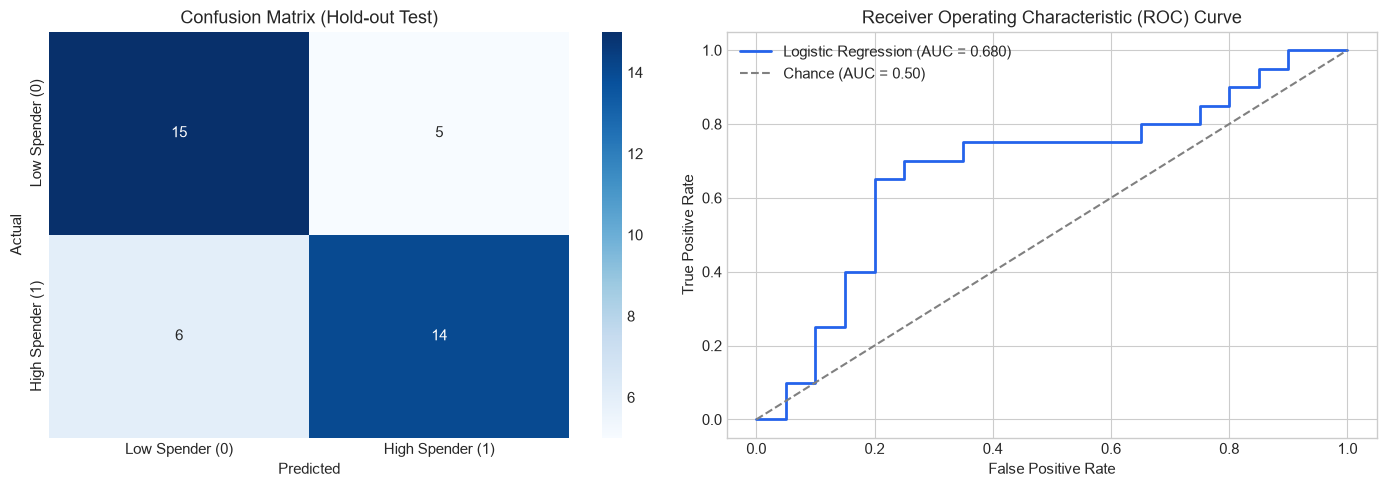

In [12]:
scaler = pipeline['scaler']
X_test_sc = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)
eval_res = evaluate_classifier(pipeline['model'], X_test_sc, y_test)
print("Hold-out Test Evaluation Metrics:")
print(eval_res['metrics_df'])

# Confusion Matrix Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(eval_res['confusion_matrix']['matrix'], annot=True, fmt='d', cmap='Blues',
            xticklabels=['Low Spender (0)', 'High Spender (1)'],
            yticklabels=['Low Spender (0)', 'High Spender (1)'], ax=axes[0])
axes[0].set_title('Confusion Matrix (Hold-out Test)')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# ROC Curve Plot
axes[1].plot(eval_res['roc_curve']['fpr'], eval_res['roc_curve']['tpr'], color='#2563EB', lw=2,
             label=f"Logistic Regression (AUC = {eval_res['roc_curve']['auc']:.3f})")
axes[1].plot([0, 1], [0, 1], color='gray', linestyle='--', label='Chance (AUC = 0.50)')
axes[1].set_title('Receiver Operating Characteristic (ROC) Curve')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend()

plt.tight_layout()
plt.show()


In [13]:
cv_res = perform_kfold_cv(X, y, n_splits=5)
print("5-Fold Stratified Cross-Validation Results:")
print(cv_res['kfold_df'])
print(f"\nMean CV Accuracy: {cv_res['mean_accuracy']*100:.2f}% ± {cv_res['std_accuracy']*100:.2f}%")
print(f"Mean CV ROC-AUC: {cv_res['mean_auc']:.3f} ± {cv_res['std_auc']:.3f}")


5-Fold Stratified Cross-Validation Results:
     Fold  Validation Score (Accuracy)  Precision    Recall  F1 Score  \
0  Fold 1                        0.600   0.590909  0.650000  0.619048   
1  Fold 2                        0.700   0.700000  0.700000  0.700000   
2  Fold 3                        0.600   0.576923  0.750000  0.652174   
3  Fold 4                        0.625   0.625000  0.714286  0.666667   
4  Fold 5                        0.725   0.727273  0.761905  0.744186   

    ROC-AUC  
0  0.582500  
1  0.782500  
2  0.590000  
3  0.588972  
4  0.754386  

Mean CV Accuracy: 65.00% ± 5.86%
Mean CV ROC-AUC: 0.660 ± 0.100


## 11. Principal Component Analysis (PCA)

Explained Variance Ratio:
  Component  Explained Variance Ratio  Explained Variance (%)  \
0      PC 1                  0.359014               35.901415   
1      PC 2                  0.337454               33.745354   

   Cumulative Variance (%)  
0                35.901415  
1                69.646769  

Component Loadings:
                    PC1_Loading  PC2_Loading
Age                    0.505724    -0.678394
Gender_Encoded         0.732834     0.011866
Annual Income (k$)     0.455191     0.734602


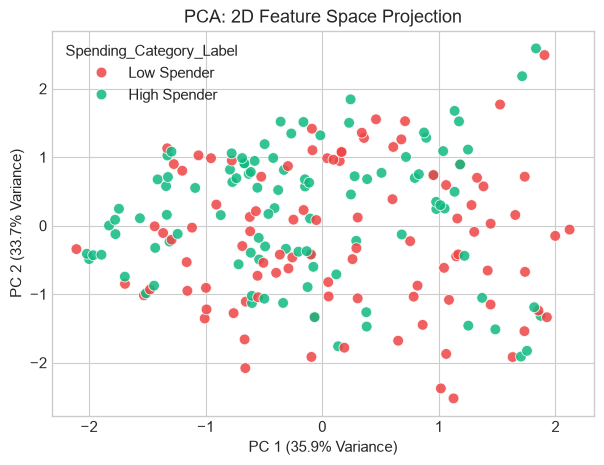

In [14]:
pca_res = perform_pca_analysis(X, y)
print("Explained Variance Ratio:")
print(pca_res['variance_summary'])
print("\nComponent Loadings:")
print(pca_res['loadings'])

fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=pca_res['pca_df'], x='Principal_Component_1', y='Principal_Component_2',
                hue='Spending_Category_Label', palette=['#EF4444', '#10B981'], s=60, alpha=0.85, ax=ax)
ax.set_title("PCA: 2D Feature Space Projection")
ax.set_xlabel(f"PC 1 ({pca_res['explained_variance_ratio'][0]*100:.1f}% Variance)")
ax.set_ylabel(f"PC 2 ({pca_res['explained_variance_ratio'][1]*100:.1f}% Variance)")
plt.show()


## 12. Non-Parametric Bootstrap Resampling (1000 Iterations)

In [15]:
boot_res = run_full_bootstrap_suite(df_clean, X, y)
print("Bootstrap Resampling Summary (B = 1000 replicates):")
boot_res['summary_df']


Bootstrap Resampling Summary (B = 1000 replicates):


,Parameter / Metric,Point Estimate,Bootstrap Mean,Bootstrap SE,95% Percentile CI,95% Normal CI
0,Mean Spending Score,50.20,50.22,1.799,"[46.57, 53.81]","[46.67, 53.73]"
1,Mean Annual Income (INR),"₹50,26,480","₹50,20,048","₹1,50,472","[₹47,28,064, ₹53,06,657]","[₹47,31,562, ₹53,21,398]"
2,Out-of-Bag Model Accuracy,63.07%,63.07%,5.84%,"[51.25%, 73.16%]",N/A (Bounded)


## 13. Customer Prediction Pipeline

In [16]:
# Example Customer: 25-year-old Female earning ₹8,00,000 per annum
example_pred = predict_customer_category(pipeline, age=25, gender='Female', annual_income_inr=800000)
print("Prediction Output for Example Profile:")
for k, v in example_pred.items():
    print(f" - {k}: {v}")


Prediction Output for Example Profile:
 - predicted_class: 1
 - category_label: High Spender
 - prob_high_percent: 65.55836121543452
 - prob_low_percent: 34.441638784565484
 - input_summary: {'Age': 25, 'Gender': 'Female', 'Annual_Income_INR': 800000, 'Annual_Income_k$': 9.63855421686747, 'Gender_Encoded': 0}


C:\Users\pratiksha yadav\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


## 14. Academic Summary & Viva-Friendly Insights

1. **Age is the dominant linear predictor:** Younger consumers have a significantly higher likelihood of being classified as High Spenders ($p = 0.0005, \text{Odds Ratio} = 0.554$).
2. **Income does not linearly determine spending:** Across Low, Medium, and High income tiers, mean spending score remains virtually identical ($p = 0.9889$ from ANOVA).
3. **Gender is not statistically significant:** Mean spending score does not differ significantly between Male and Female customers ($t = -0.8190, p = 0.4137$).
4. **Generalization Stability:** Logistic Regression achieves **72.50%** test accuracy and **65.00% ± 5.86%** across 5-fold cross-validation.
